# SmartCheck – Gatecheck Weekly Report: RBPL vs FCPL
Covers **Visitors and Vendors** for both branches, then a **side-by-side comparison**.

In [1]:
# ---- CELL 1: imports ----
import pandas as pd, numpy as np, re, os
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 13, 'axes.titleweight': 'bold', 'font.size': 10})
COLORS = {'Visitors': '#1f4e79', 'Vendors': '#2e9c8f'}
BRANCH_COLORS = {'RBPL': '#1f4e79', 'FCPL': '#e08a1e'}

In [2]:
# ---- CELL 2: SETTINGS 
BRANCHES = {
    'RBPL': {
        'Visitors': r'C:\Users\Moses\Downloads\VisitorExcel_2026_10_29_9_24_6_341.xlsx',
        'Vendors':  r'C:\Users\Moses\Downloads\VisitorExcel_2026_10_29_9_24_51_55.xlsx',
    },
    'FCPL': {
        'Visitors': r'C:\Users\Moses\Downloads\VisitorExcel_2026_10_29_9_17_8_770.xlsx',
        'Vendors':  r'C:\Users\Moses\Downloads\VisitorExcel_2026_10_29_9_17_52_72.xlsx',
    },
}
OUTPUT_ROOT = 'gatecheck_output'      # a sub-folder per branch + the comparison file are saved here
LONG_STAY_HOURS = 4                   # stays longer than this are flagged
os.makedirs(OUTPUT_ROOT, exist_ok=True)

## 1. Loader & cleaner

In [3]:
# ---- CELL 3: loader + cleaner 
DT_FMT = '%d-%m-%Y %I:%M %p'

def load_gate(path, kind):
    """Read a SmartCheck gate-entry export. Returns (df, period_text) or (None, None) if file missing/empty."""
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        print(f'⚠ {kind}: file missing or empty -> skipped ({path})'); return None, None
    raw = pd.read_excel(path, header=None)
    period = str(raw.iloc[0, 0])
    hdr = raw.index[raw.iloc[:, 0].astype(str).str.strip().eq('SNO')]
    if len(hdr) == 0:
        print(f'⚠ {kind}: header row (SNO) not found -> skipped'); return None, None
    df = raw.iloc[hdr[0] + 1:].copy(); df.columns = raw.iloc[hdr[0]].astype(str).str.strip()
    df = df[pd.to_numeric(df['SNO'], errors='coerce').notna()].reset_index(drop=True)
    if df.empty:
        print(f'ℹ {kind}: no records this week'); return None, period
    return clean_gate(df, kind), period

def clean_gate(df, kind):
    df = df.copy()
    for c in df.select_dtypes(include=['object','string']): df[c] = df[c].astype(str).str.strip().replace({'-': np.nan, 'nan': np.nan, '': np.nan, 'None': np.nan})
    df['Group'] = kind
    df['TimeIn']  = pd.to_datetime(df['TimeIn'],  format=DT_FMT, errors='coerce')
    df['TimeOut'] = pd.to_datetime(df['TimeOut'], format=DT_FMT, errors='coerce')
    df['Date'] = df['TimeIn'].dt.normalize(); df['Day'] = df['TimeIn'].dt.day_name(); df['Hour'] = df['TimeIn'].dt.hour
    df['StayMins'] = (df['TimeOut'] - df['TimeIn']).dt.total_seconds() / 60
    df.loc[df['StayMins'] < 0, 'StayMins'] = np.nan
    df['StillInside'] = df['TimeOut'].isna()
    df['Persons(+)'] = pd.to_numeric(df['Persons(+)'], errors='coerce').fillna(0).astype(int)
    df['Headcount'] = 1 + df['Persons(+)']                       # the visitor + people accompanying
    df['NameKey'] = df['Name'].str.lower().str.replace(r'[^a-z ]', '', regex=True).str.strip()
    # Host company = text in last brackets of 'Person To Meet'  e.g. "Femi (Greenwich Merchant Bank )"
    df['HostCompany'] = df['Person To Meet'].str.extract(r'\(([^()]*)\)\s*$')[0].str.strip()
    df['HostPerson']  = df['Person To Meet'].str.replace(r'\([^()]*\)\s*$', '', regex=True).str.strip()
    df['Category']    = df['Category'].str.title()
    df['Purpose of Meet'] = df['Purpose of Meet'].str.title()
    df['Belongings']  = df['Belongings/ Tools/ Remarks'].str.lower()
    df['HasLaptop']   = df['Belongings'].str.contains('laptop|ipad|macbook', na=False)
    df['HasVehicle']  = df['Vehicle Type'].notna()
    df['GovtIDCaptured'] = df['Govt ID'].str.contains(r'\d', na=False)   # 'Aadhar -' with no number = not captured
    # Bulk sign-out: 4+ people signed out in the same minute (security clearing the gate at closing) -> stay time is overstated
    df['BulkSignOut'] = df.groupby('TimeOut')['TimeOut'].transform('size').ge(4) & df['TimeOut'].notna()
    return df

## 2. Analysis for one branch (runs automatically for each branch below)


In [4]:
def analyse(BRANCH):
    """Runs the full gatecheck analysis for one branch."""
    FILES = BRANCHES[BRANCH]
    OUTPUT_DIR = f'{OUTPUT_ROOT}/{BRANCH}'; os.makedirs(OUTPUT_DIR, exist_ok=True)
    print('=' * 70); print(f'  {BRANCH}'); print('=' * 70)
    frames, periods = {}, {}
    for kind, path in FILES.items():
        d, p = load_gate(path, kind)
        if d is not None: frames[kind] = d
        if p: periods[kind] = p

    if not frames:
        print(f'⚠ {BRANCH}: no data loaded – check the file paths in Cell 2'); return None
    ALL = pd.concat(frames.values(), ignore_index=True)
    print('Report period (from SmartCheck):', sorted(set(periods.values())))
    print({k: len(v) for k, v in frames.items()}, '| total records:', len(ALL))

    print('\n--- Coverage check ---')
    cov = ALL.groupby('Group')['Date'].agg(['min', 'max', 'nunique']).rename(columns={'nunique': 'days_with_data'})
    print(cov)
    week_start = ALL['Date'].min() - pd.Timedelta(days=ALL['Date'].min().weekday())
    expected = pd.date_range(week_start, periods=5)
    missing_days = [d.strftime('%a %d-%b') for d in expected if d not in set(ALL['Date'])]
    if missing_days: print('\n⚠ No records on:', ', '.join(missing_days), '-> check your export date range (end date should be the Saturday).')
    else: print('\n✔ All five working days (Mon–Fri) are present.')

    print('\n--- 1. Headline numbers ---')
    def kpis(d):
        return pd.Series({
            'Entries (records)': len(d),
            'Unique people': d['NameKey'].nunique(),
            'Total headcount (incl. accompanying)': int(d['Headcount'].sum()),
            'Avg stay (mins)': round(d['StayMins'].mean(), 0),
            'Median stay (mins)': round(d['StayMins'].median(), 0),
            f'Stays > {LONG_STAY_HOURS} hrs': int((d['StayMins'] > LONG_STAY_HOURS * 60).sum()),
            'Bulk sign-outs (stay time unreliable)': int(d['BulkSignOut'].sum()),
            'Not signed out': int(d['StillInside'].sum()),
            'With laptop/iPad declared': int(d['HasLaptop'].sum()),
            'Arrived with vehicle': int(d['HasVehicle'].sum()),
        })
    summary = pd.concat({k: kpis(v) for k, v in frames.items()}, axis=1)
    summary['All'] = kpis(ALL)
    display(summary)

    print('\n--- 2. Daily traffic ---')
    day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
    daily = ALL.pivot_table(index='Day', columns='Group', values='SNO', aggfunc='count', fill_value=0).reindex(day_order).fillna(0).astype(int)
    daily['Total'] = daily.sum(axis=1)
    display(daily)
    ax = daily.drop(columns='Total').plot(kind='bar', stacked=True, color=[COLORS[c] for c in daily.columns[:-1]], rot=0)
    for i, t in enumerate(daily['Total']): ax.text(i, t + 0.5, str(t), ha='center', fontweight='bold')
    ax.set_title(f'{BRANCH}: Gate entries per day'); ax.set_xlabel(''); ax.set_ylabel('Entries'); ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/01_daily_entries.png', dpi=150); plt.show()
    busiest = daily['Total'].idxmax(); print(f'Busiest day: {busiest} ({daily.loc[busiest, "Total"]} entries); quietest: {daily[daily.Total>0]["Total"].idxmin()}')

    print('\n--- 3. Peak hours ---')
    hourly = ALL.groupby('Hour').size().reindex(range(7, 19), fill_value=0)
    ax = hourly.plot(kind='bar', color=COLORS['Visitors'], rot=0)
    ax.set_xticklabels([f'{h}:00' for h in hourly.index]); ax.set_title(f'{BRANCH}: Arrivals by hour of day'); ax.set_xlabel(''); ax.set_ylabel('Arrivals')
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/02_hourly_arrivals.png', dpi=150); plt.show()
    pk = hourly.idxmax(); print(f'Peak hour: {pk}:00–{pk+1}:00 ({hourly.max()} arrivals, {hourly.max()/hourly.sum():.0%} of all entries)')
    heat = ALL.pivot_table(index='Day', columns='Hour', values='SNO', aggfunc='count', fill_value=0).reindex(day_order).fillna(0)
    display(heat)

    print('\n--- 4. Host companies ---')
    hosts = ALL.groupby(['HostCompany', 'Group']).size().unstack(fill_value=0)
    hosts['Total'] = hosts.sum(axis=1); hosts = hosts.sort_values('Total', ascending=False)
    display(hosts.head(10))
    top = hosts.head(8).drop(columns='Total')[::-1]
    ax = top.plot(kind='barh', stacked=True, color=[COLORS[c] for c in top.columns])
    ax.set_title(f'{BRANCH}: Most-visited host companies'); ax.set_ylabel('')
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/03_host_companies.png', dpi=150); plt.show()
    print(f'{hosts.index[0]} received {hosts.iloc[0]["Total"]/len(ALL):.0%} of all entries.  Entries with no host company recorded: {ALL.HostCompany.isna().sum()}')

    print('\n--- 5. Purpose & check-in method ---')
    purpose = ALL['Purpose of Meet'].fillna('Not recorded').value_counts()
    method = ALL.groupby(['Type', 'Group']).size().unstack(fill_value=0); method['Total'] = method.sum(axis=1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    purpose.plot(kind='barh', ax=ax[0], color=COLORS['Visitors']).invert_yaxis(); ax[0].set_title('Purpose of visit')
    mt = method['Total'].sort_values(); mt.plot(kind='barh', ax=ax[1], color=COLORS['Vendors']); ax[1].set_title('Check-in method'); ax[1].set_ylabel('')
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/04_purpose_method.png', dpi=150); plt.show()
    display(method.sort_values('Total', ascending=False))
    walk = (ALL['Type'].str.lower() == 'walk-in').mean()
    print(f'Walk-ins (not pre-registered): {walk:.0%} of entries | Purpose not recorded: {ALL["Purpose of Meet"].isna().mean():.0%}')

    print('\n--- 6. Time on premises ---')
    stay = ALL.dropna(subset=['StayMins'])
    bulk = int(ALL['BulkSignOut'].sum())
    print(f'ℹ {bulk} entries ({bulk/len(ALL):.0%}) were signed out in bulk (4+ people in the same minute, usually at closing). Their stay time is overstated; see "reliable" stats below.')
    print('All entries:'); print(stay.groupby('Group')['StayMins'].describe()[['count', 'mean', '50%', 'max']].round(0).rename(columns={'50%': 'median'}))
    fig, ax = plt.subplots()
    bins = [0, 15, 30, 60, 120, 240, 600]; labels = ['<15m', '15–30m', '30–60m', '1–2h', '2–4h', '>4h']
    dist = pd.cut(stay['StayMins'], bins, labels=labels).value_counts().reindex(labels)
    dist.plot(kind='bar', ax=ax, color=COLORS['Visitors'], rot=0); ax.set_title(f'{BRANCH}: How long people stay'); ax.set_xlabel(''); ax.set_ylabel('Entries')
    plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/05_stay_duration.png', dpi=150); plt.show()

    real = stay[~stay['BulkSignOut']]
    print('\nExcluding bulk sign-outs (more reliable):'); print(real.groupby('Group')['StayMins'].describe()[['count', 'mean', '50%', 'max']].round(0).rename(columns={'50%': 'median'}))
    long_stays = ALL[ALL['StayMins'] > LONG_STAY_HOURS * 60][['Group', 'Name', 'HostCompany', 'TimeIn', 'TimeOut', 'StayMins', 'BulkSignOut']].sort_values('StayMins', ascending=False)
    long_stays['StayMins'] = long_stays['StayMins'].round(0)
    print(f'\nStays longer than {LONG_STAY_HOURS} hrs ({int(long_stays.BulkSignOut.sum())} of {len(long_stays)} were bulk sign-outs):'); display(long_stays)

    print('\n--- 7. Exceptions for follow-up ---')
    not_out = ALL[ALL['StillInside']][['Group', 'Name', 'HostCompany', 'TimeIn']]
    repeat = (ALL.groupby('NameKey').agg(Name=('Name', 'first'), Visits=('SNO', 'count'), Days=('Date', 'nunique'), Group=('Group', 'first'))
              .query('Visits > 1').sort_values('Visits', ascending=False))
    big_groups = ALL[ALL['Persons(+)'] >= 3][['Group', 'Name', 'HostCompany', 'Persons(+)', 'TimeIn']]
    dq = pd.Series({
        'Category blank': ALL['Category'].isna().sum(),
        'Purpose of visit blank': ALL['Purpose of Meet'].isna().sum(),
        'Host company missing': ALL['HostCompany'].isna().sum(),
        'Email not captured': ALL['Email'].isna().sum(),
        'Govt ID number not captured': (~ALL['GovtIDCaptured']).sum(),
        'No sign-out time': ALL['StillInside'].sum(),
    }).to_frame('Records'); dq['% of entries'] = (dq['Records'] / len(ALL) * 100).round(0)

    print('Records with no sign-out time (verify they left):'); display(not_out)
    print('Repeat visitors (same name, >1 entry this week):'); display(repeat.head(10))
    print('Large groups (3+ accompanying):'); display(big_groups)
    print('Data-quality gaps:'); display(dq)

    print('\n--- 8. Talking points ---')
    best = daily['Total'].idxmax(); share = lambda g: len(frames[g]) / len(ALL) if g in frames else 0
    pts = [
        f'{BRANCH} gate recorded {len(ALL)} entries this week ({int(ALL.Headcount.sum())} people including accompanying persons): '
        + ', '.join(f'{len(v)} {k.lower()}' for k, v in frames.items()) + '.',
        f'Busiest day was {best} with {daily.loc[best, "Total"]} entries; peak arrival hour was {pk}:00–{pk+1}:00 ({hourly.max()/hourly.sum():.0%} of arrivals).',
        f'{hosts.index[0]} was the most-visited host ({hosts.iloc[0]["Total"]/len(ALL):.0%} of entries).',
        f'Typical stay was {real.StayMins.median():.0f} mins (average {real.StayMins.mean():.0f}), excluding {bulk} entries signed out in bulk at closing. {len(long_stays)} stay(s) exceeded {LONG_STAY_HOURS} hrs, {int(long_stays.BulkSignOut.sum())} of them bulk sign-outs.',
        f'{len(not_out)} record(s) had no sign-out time – security should confirm these people left.' if len(not_out) else 'Every entry has a sign-out time.',
        f'{dq.loc["Govt ID number not captured", "% of entries"]:.0f}% of entries have no government ID number captured; {dq.loc["Category blank", "Records"]} have no category and {dq.loc["Purpose of visit blank", "Records"]} have no purpose recorded.',
    ]
    for p in pts: print('•', p)

    print('\n--- 9. Export ---')
    xl = f'{OUTPUT_DIR}/Gatecheck_{BRANCH}_weekly_summary.xlsx'
    with pd.ExcelWriter(xl) as w:
        summary.to_excel(w, sheet_name='KPIs'); daily.to_excel(w, sheet_name='Daily'); heat.to_excel(w, sheet_name='Day x Hour')
        hosts.to_excel(w, sheet_name='Host companies'); long_stays.to_excel(w, sheet_name='Long stays', index=False)
        not_out.to_excel(w, sheet_name='No sign-out', index=False); repeat.to_excel(w, sheet_name='Repeat visitors')
        dq.to_excel(w, sheet_name='Data quality')
        ALL.drop(columns=['NameKey']).to_excel(w, sheet_name='Clean data', index=False)
    print('Saved:', os.path.abspath(OUTPUT_DIR)); print(*sorted(os.listdir(OUTPUT_DIR)), sep='\n  ')

    return dict(BRANCH=BRANCH, ALL=ALL, frames=frames, summary=summary, daily=daily, hourly=hourly, hosts=hosts, real=real, bulk=bulk,
                long_stays=long_stays, not_out=not_out, repeat=repeat, dq=dq, pk=pk, pts=pts, output_dir=OUTPUT_DIR)

## 3. Run RBPL and FCPL

  RBPL
Report period (from SmartCheck): ['Gate Entry Report (Vendor)', 'Gate Entry Report (Visitor)']
{'Visitors': 201, 'Vendors': 16} | total records: 217

--- Coverage check ---
                min        max  days_with_data
Group                                         
Vendors  2026-10-19 2026-10-23               5
Visitors 2026-10-19 2026-10-23               5

✔ All five working days (Mon–Fri) are present.

--- 1. Headline numbers ---


,Visitors,Vendors,All
Entries (records),201.0,16.0,217.0
Unique people,184.0,15.0,198.0
Total headcount (incl. accompanying),291.0,31.0,322.0
Avg stay (mins),124.0,84.0,121.0
Median stay (mins),55.0,37.0,54.0
Stays > 4 hrs,36.0,2.0,38.0
Bulk sign-outs (stay time unreliable),38.0,0.0,38.0
Not signed out,9.0,1.0,10.0
With laptop/iPad declared,24.0,2.0,26.0
Arrived with vehicle,7.0,2.0,9.0



--- 2. Daily traffic ---


Group,Vendors,Visitors,Total
Day,,,
Monday,6,31,37
Tuesday,3,37,40
Wednesday,3,45,48
Thursday,2,44,46
Friday,2,44,46


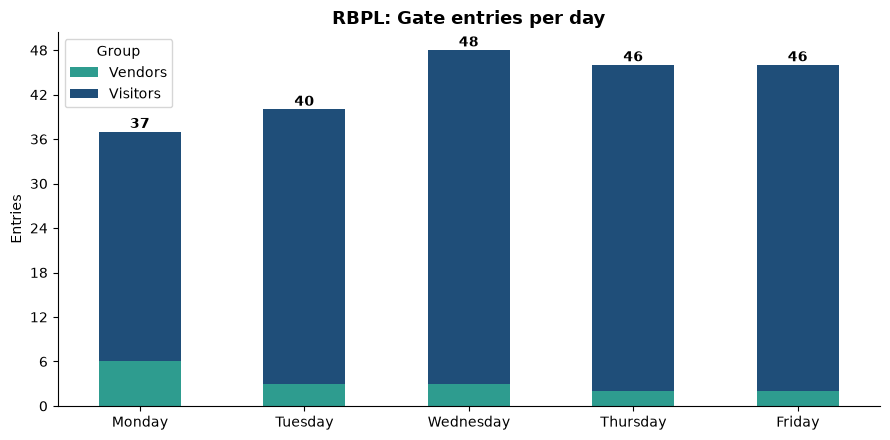

Busiest day: Wednesday (48 entries); quietest: Monday

--- 3. Peak hours ---


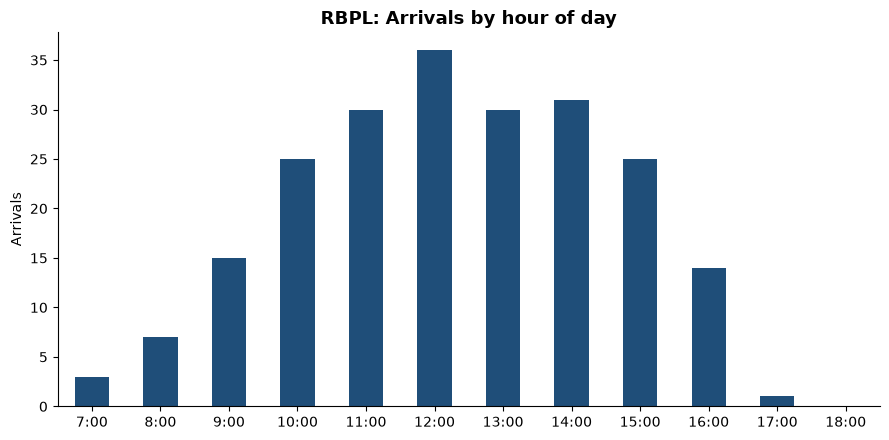

Peak hour: 12:00–13:00 (36 arrivals, 17% of all entries)


Hour,7,8,9,10,11,12,13,14,15,16,17
Day,,,,,,,,,,,
Monday,0,0,2,3,5,6,3,7,7,4,0
Tuesday,0,0,4,6,7,3,5,6,5,4,0
Wednesday,0,3,5,7,3,10,8,8,2,2,0
Thursday,0,1,2,5,10,9,7,2,8,2,0
Friday,3,3,2,4,5,8,7,8,3,2,1



--- 4. Host companies ---


Group,Vendors,Visitors,Total
HostCompany,,,
Greenwich Merchant Bank,4,49,53
BETAGLASS,5,31,36
Sunbeth Global Concept,1,27,28
Optiva Capital Partners,1,19,20
GCT Group,1,11,12
Red Bull Nigeria Limited,2,10,12
Sunbeth Energy,0,11,11
Qucoon,0,10,10
MICHELLIN,0,8,8


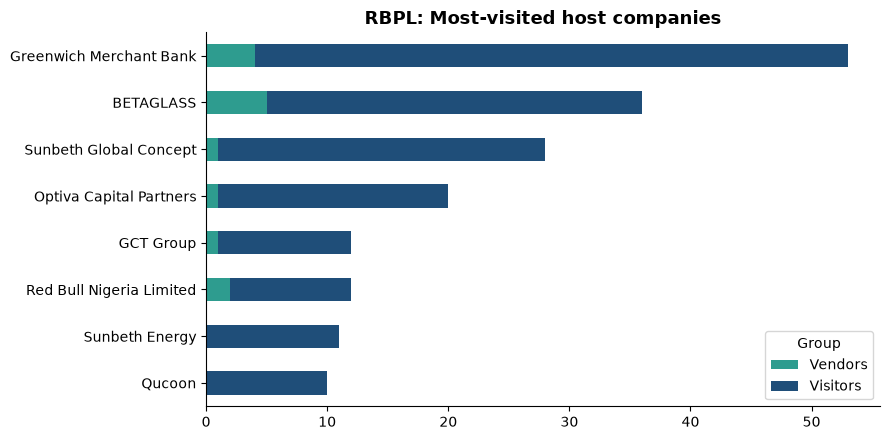

Greenwich Merchant Bank received 24% of all entries.  Entries with no host company recorded: 0

--- 5. Purpose & check-in method ---


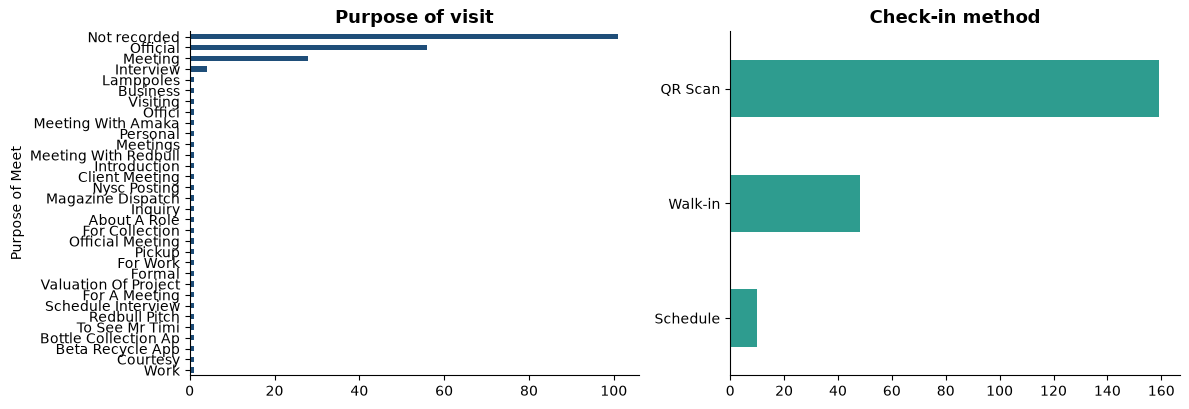

Group,Vendors,Visitors,Total
Type,,,
QR Scan,16,143,159
Walk-in,0,48,48
Schedule,0,10,10


Walk-ins (not pre-registered): 22% of entries | Purpose not recorded: 47%

--- 6. Time on premises ---
ℹ 38 entries (18%) were signed out in bulk (4+ people in the same minute, usually at closing). Their stay time is overstated; see "reliable" stats below.
All entries:
          count   mean  median    max
Group                                
Vendors    15.0   84.0    37.0  496.0
Visitors  192.0  124.0    55.0  549.0


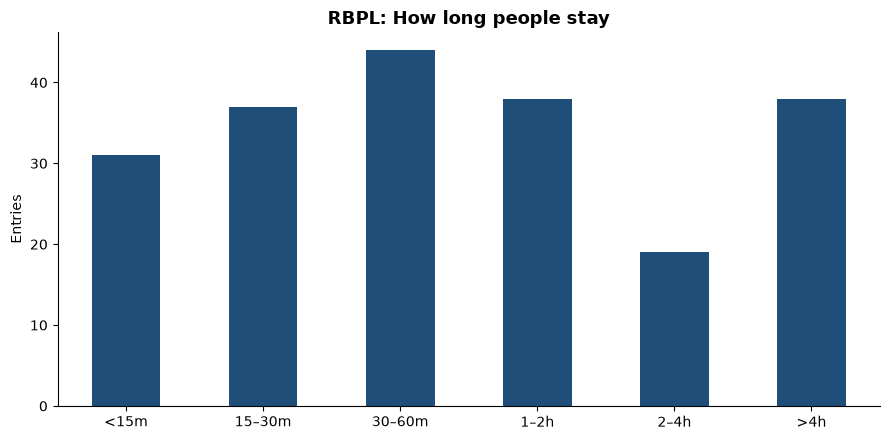


Excluding bulk sign-outs (more reliable):
          count  mean  median    max
Group                               
Vendors    15.0  84.0    37.0  496.0
Visitors  154.0  80.0    43.0  549.0

Stays longer than 4 hrs (25 of 38 were bulk sign-outs):


2,Group,Name,HostCompany,TimeIn,TimeOut,StayMins,BulkSignOut
157,Visitors,Joseph,Red Bull Nigeria Limited,2026-10-23 07:52:00,2026-10-23 17:01:00,549.0,False
159,Visitors,Josiah,Qucoon,2026-10-23 07:59:00,2026-10-23 17:02:00,543.0,True
158,Visitors,Amusa Latifat Eniola,Sunbeth Global Concept,2026-10-23 07:59:00,2026-10-23 17:01:00,542.0,False
162,Visitors,Deborah,Qucoon,2026-10-23 08:22:00,2026-10-23 17:02:00,520.0,True
70,Visitors,Ifeoluwa,Sunbeth Global Concept,2026-10-21 08:52:00,2026-10-21 17:23:00,511.0,True
160,Visitors,Bolarin Akintade,BETAGLASS,2026-10-23 08:39:00,2026-10-23 17:02:00,503.0,True
211,Vendors,Damilare,Red Bull Nigeria Limited,2026-10-21 09:15:00,2026-10-21 17:31:00,496.0,False
113,Visitors,Lawal Baseet Olalekan,MICHELLIN,2026-10-22 08:58:00,2026-10-22 17:11:00,493.0,True
114,Visitors,Saheed,MICHELLIN,2026-10-22 09:13:00,2026-10-22 17:11:00,478.0,True
1,Visitors,Damilare,Red Bull Nigeria Limited,2026-10-19 09:22:00,2026-10-19 17:16:00,474.0,False



--- 7. Exceptions for follow-up ---
Records with no sign-out time (verify they left):


2,Group,Name,HostCompany,TimeIn
128,Visitors,Mr Bolaji Osunsanya,BETAGLASS,2026-10-22 15:51:00
129,Visitors,Ms Sola Carrena,BETAGLASS,2026-10-22 15:46:00
130,Visitors,Ms Lola Adefope,BETAGLASS,2026-10-22 15:34:00
131,Visitors,Mrs Olabisi Abimbola,BETAGLASS,2026-10-22 15:02:00
153,Visitors,Sanusi,Optiva Capital Partners,2026-10-22 15:19:00
193,Visitors,Okeolajide Oluwatosin,Sunbeth Energy,2026-10-23 14:43:00
196,Visitors,Mr Ugo,MICHELLIN,2026-10-23 15:17:00
199,Visitors,Ray,Greenwich Merchant Bank,2026-10-23 16:21:00
200,Visitors,Diamonte,Red Bull Nigeria Limited,2026-10-23 17:09:00
213,Vendors,Damilare,Red Bull Nigeria Limited,2026-10-22 09:11:00


Repeat visitors (same name, >1 entry this week):


...

,Records,% of entries
Category blank,25,12.0
Purpose of visit blank,101,47.0
Host company missing,0,0.0
Email not captured,117,54.0
Govt ID number not captured,217,100.0
No sign-out time,10,5.0



--- 8. Talking points ---
• RBPL gate recorded 217 entries this week (322 people including accompanying persons): 201 visitors, 16 vendors.
• Busiest day was Wednesday with 48 entries; peak arrival hour was 12:00–13:00 (17% of arrivals).
• Greenwich Merchant Bank was the most-visited host (24% of entries).
• Typical stay was 43 mins (average 80), excluding 38 entries signed out in bulk at closing. 38 stay(s) exceeded 4 hrs, 25 of them bulk sign-outs.
• 10 record(s) had no sign-out time – security should confirm these people left.
• 100% of entries have no government ID number captured; 25 have no category and 101 have no purpose recorded.

--- 9. Export ---
Saved: C:\Users\Moses\Downloads\gatecheck_output\RBPL
01_daily_entries.png
  02_hourly_arrivals.png
  03_host_companies.png
  04_purpose_method.png
  05_stay_duration.png
  Gatecheck_RBPL_weekly_summary.xlsx
  FCPL
Report period (from SmartCheck): ['Gate Entry Report (Vendor)', 'Gate Entry Report (Visitor)']
{'Visitors': 60, 'Vendo

,Visitors,Vendors,All
Entries (records),60.0,29.0,89.0
Unique people,58.0,27.0,85.0
Total headcount (incl. accompanying),91.0,33.0,124.0
Avg stay (mins),85.0,77.0,82.0
Median stay (mins),56.0,50.0,56.0
Stays > 4 hrs,1.0,2.0,3.0
Bulk sign-outs (stay time unreliable),0.0,0.0,0.0
Not signed out,6.0,0.0,6.0
With laptop/iPad declared,0.0,0.0,0.0
Arrived with vehicle,3.0,0.0,3.0



--- 2. Daily traffic ---


Group,Vendors,Visitors,Total
Day,,,
Monday,4,16,20
Tuesday,4,6,10
Wednesday,8,12,20
Thursday,9,13,22
Friday,4,13,17


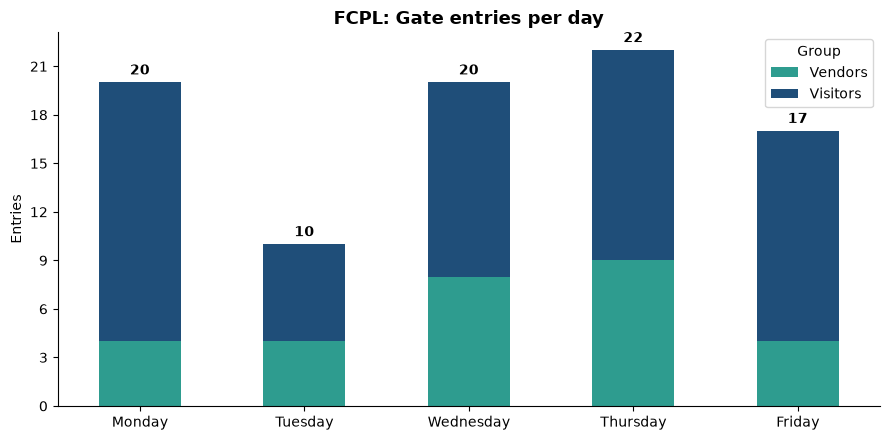

Busiest day: Thursday (22 entries); quietest: Tuesday

--- 3. Peak hours ---


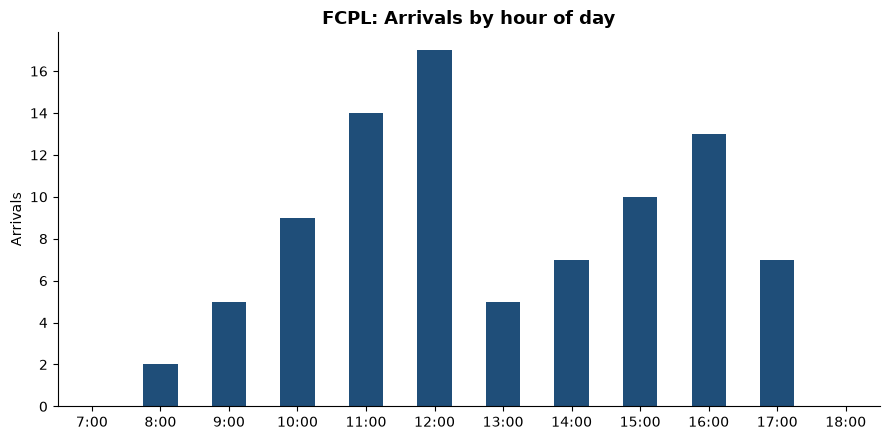

Peak hour: 12:00–13:00 (17 arrivals, 19% of all entries)


Hour,8,9,10,11,12,13,14,15,16,17
Day,,,,,,,,,,
Monday,0,3,3,1,6,0,0,3,2,2
Tuesday,2,0,1,3,0,0,3,0,0,1
Wednesday,0,0,0,6,4,1,1,1,6,1
Thursday,0,1,3,2,3,2,3,3,3,2
Friday,0,1,2,2,4,2,0,3,2,1



--- 4. Host companies ---


Group,Vendors,Visitors,Total
HostCompany,,,
Greenwich Capital Limited,3,25,28
CHURCHGATE,8,5,13
Greenwich Holdings Limited,5,7,12
AFRICA PLUS PARTNERS NIGERIA LIMITED,0,7,7
UHURU,3,3,6
BUCCH ENERGY LIMITED,2,3,5
GTL Properties Limited,2,2,4
POWERGAS,3,1,4
03Capital Nigeria Limited,2,1,3


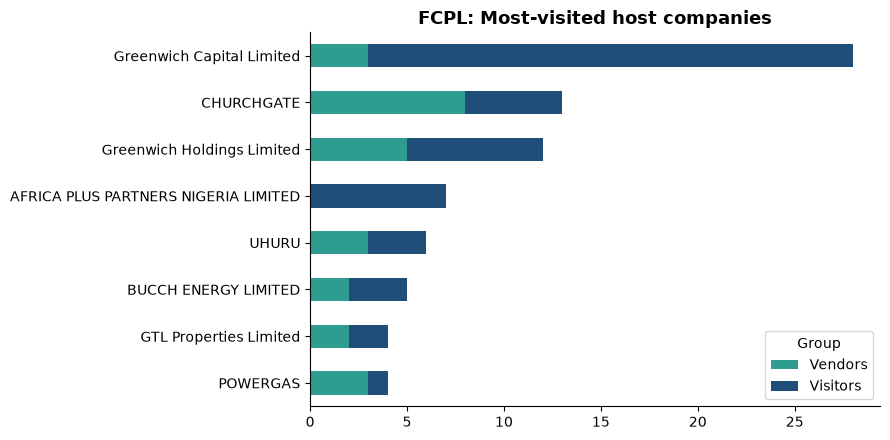

Greenwich Capital Limited received 31% of all entries.  Entries with no host company recorded: 0

--- 5. Purpose & check-in method ---


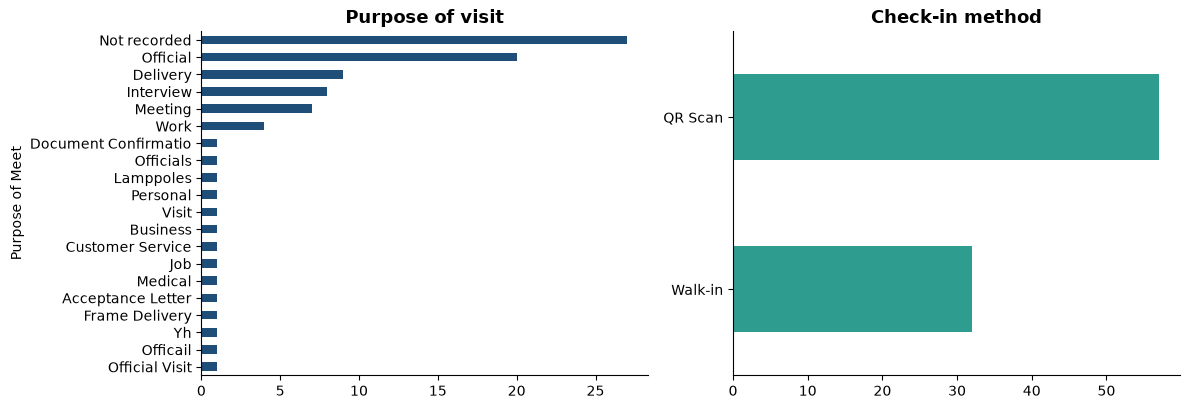

Group,Vendors,Visitors,Total
Type,,,
QR Scan,5,52,57
Walk-in,24,8,32


Walk-ins (not pre-registered): 36% of entries | Purpose not recorded: 30%

--- 6. Time on premises ---
ℹ 0 entries (0%) were signed out in bulk (4+ people in the same minute, usually at closing). Their stay time is overstated; see "reliable" stats below.
All entries:
          count  mean  median    max
Group                               
Vendors    29.0  77.0    50.0  347.0
Visitors   54.0  85.0    56.0  532.0


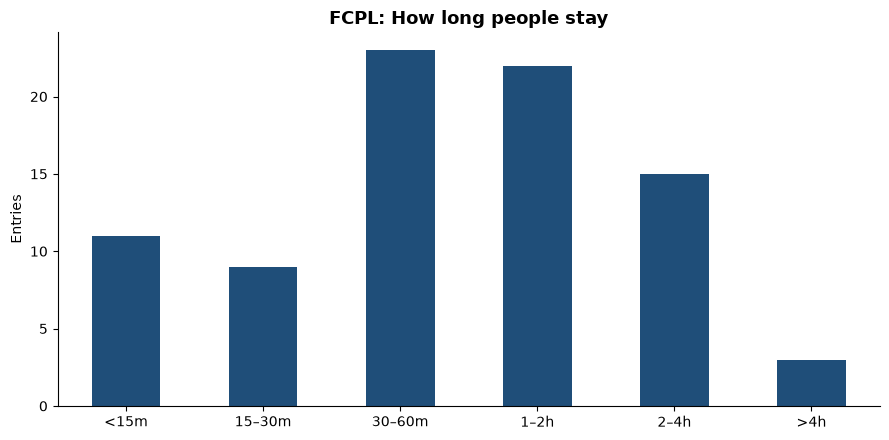


Excluding bulk sign-outs (more reliable):
          count  mean  median    max
Group                               
Vendors    29.0  77.0    50.0  347.0
Visitors   54.0  85.0    56.0  532.0

Stays longer than 4 hrs (0 of 3 were bulk sign-outs):


2,Group,Name,HostCompany,TimeIn,TimeOut,StayMins,BulkSignOut
16,Visitors,Daniel,Carolina Logistics,2026-10-20 08:52:00,2026-10-20 17:44:00,532.0,False
66,Vendors,Victor Chukwuma,03Capital Nigeria Limited,2026-10-20 11:53:00,2026-10-20 17:40:00,347.0,False
60,Vendors,Matthew Alade,CHURCHGATE,2026-10-19 10:35:00,2026-10-19 15:06:00,271.0,False



--- 7. Exceptions for follow-up ---
Records with no sign-out time (verify they left):


2,Group,Name,HostCompany,TimeIn
11,Visitors,Freda Nobei,Greenwich Holdings Limited,2026-10-19 15:44:00
13,Visitors,Chinelo DareAdelusi,Greenwich Capital Limited,2026-10-19 16:49:00
14,Visitors,Oluwabusola Salami,Greenwich Capital Limited,2026-10-19 17:35:00
15,Visitors,Rohit Maini,CHURCHGATE,2026-10-19 17:39:00
33,Visitors,Adegboyega Victoria,Greenwich Capital Limited,2026-10-21 17:32:00
59,Visitors,Oluwatosin Olatunji,Greenwich Merchant Bank,2026-10-23 17:21:00


Repeat visitors (same name, >1 entry this week):


...

Large groups (3+ accompanying):


2,Group,Name,HostCompany,Persons(+),TimeIn
5,Visitors,Chimanma Ekeh,AFRICA PLUS PARTNERS NIGERIA LIMITED,3,2026-10-19 12:38:00
10,Visitors,Temitope,Greenwich Capital Limited,10,2026-10-19 15:05:00


Data-quality gaps:


,Records,% of entries
Category blank,89,100.0
Purpose of visit blank,27,30.0
Host company missing,0,0.0
Email not captured,53,60.0
Govt ID number not captured,89,100.0
No sign-out time,6,7.0



--- 8. Talking points ---
• FCPL gate recorded 89 entries this week (124 people including accompanying persons): 60 visitors, 29 vendors.
• Busiest day was Thursday with 22 entries; peak arrival hour was 12:00–13:00 (19% of arrivals).
• Greenwich Capital Limited was the most-visited host (31% of entries).
• Typical stay was 56 mins (average 82), excluding 0 entries signed out in bulk at closing. 3 stay(s) exceeded 4 hrs, 0 of them bulk sign-outs.
• 6 record(s) had no sign-out time – security should confirm these people left.
• 100% of entries have no government ID number captured; 89 have no category and 27 have no purpose recorded.

--- 9. Export ---
Saved: C:\Users\Moses\Downloads\gatecheck_output\FCPL
01_daily_entries.png
  02_hourly_arrivals.png
  03_host_companies.png
  04_purpose_method.png
  05_stay_duration.png
  Gatecheck_FCPL_weekly_summary.xlsx

Branches completed: ['RBPL', 'FCPL']


In [5]:
results = {}
for b in BRANCHES:
    r = analyse(b)
    if r is not None: results[b] = r
print('\nBranches completed:', list(results))

## 4. Side-by-side comparison (for the COO)

In [6]:
# ---- comparison table ----
assert results, 'No branch loaded any data – check the file paths in Cell 2.'
def pct(a, b): return f'{a / b:.0%}' if b else '–'
rows = {}
for b, r in results.items():
    A, d, h = r['ALL'], r['daily'], r['hosts']
    rows[b] = {
        'Total entries': len(A),
        'Visitors': len(r['frames'].get('Visitors', [])), 'Vendors': len(r['frames'].get('Vendors', [])),
        'Total headcount (incl. accompanying)': int(A['Headcount'].sum()),
        'Unique people': A['NameKey'].nunique(),
        'Busiest day': f"{d['Total'].idxmax()} ({d['Total'].max()})",
        'Peak arrival hour': f"{r['pk']}:00–{r['pk']+1}:00",
        'Top host company': f"{h.index[0]} ({pct(h.iloc[0]['Total'], len(A))})",
        'Typical stay, mins (median, excl. bulk sign-outs)': round(r['real']['StayMins'].median()),
        'Entries signed out in bulk': r['bulk'],
        'Not signed out': int(A['StillInside'].sum()),
        'Walk-ins (% of entries)': pct((A['Type'].str.lower() == 'walk-in').sum(), len(A)),
        'Purpose not recorded': pct(A['Purpose of Meet'].isna().sum(), len(A)),
        'Email not captured': pct(A['Email'].isna().sum(), len(A)),
        'Govt ID number not captured': pct((~A['GovtIDCaptured']).sum(), len(A)),
    }
comparison = pd.DataFrame(rows)
display(comparison)

,RBPL,FCPL
Total entries,217,89
Visitors,201,60
Vendors,16,29
Total headcount (incl. accompanying),322,124
Unique people,198,85
Busiest day,Wednesday (48),Thursday (22)
Peak arrival hour,12:00–13:00,12:00–13:00
Top host company,Greenwich Merchant Bank (24%),Greenwich Capital Limited (31%)
"Typical stay, mins (median, excl. bulk sign-outs)",43,56
Entries signed out in bulk,38,0


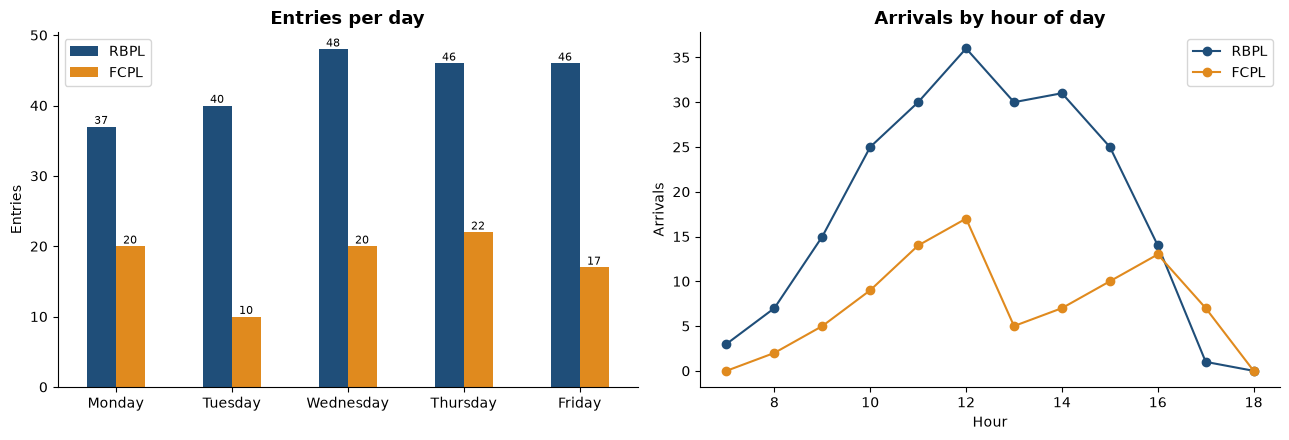

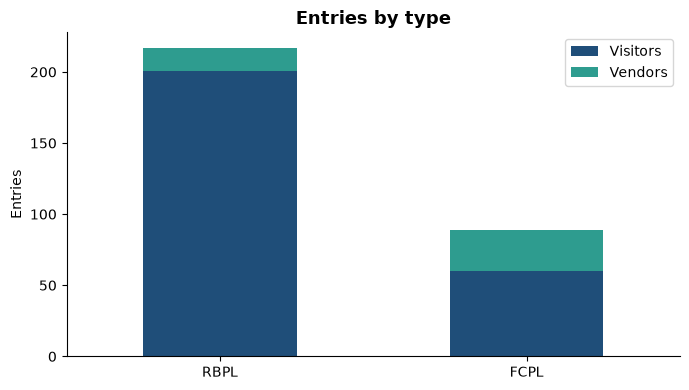

In [7]:
# ---- comparison charts (same scale for both branches) ----
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
dd = pd.DataFrame({b: r['daily']['Total'] for b, r in results.items()}).reindex(day_order).fillna(0)
dd.plot(kind='bar', ax=ax[0], rot=0, color=[BRANCH_COLORS[c] for c in dd.columns]); ax[0].set_title('Entries per day'); ax[0].set_xlabel(''); ax[0].set_ylabel('Entries')
for c in ax[0].containers: ax[0].bar_label(c, fontsize=8)
hh = pd.DataFrame({b: r['hourly'] for b, r in results.items()})
hh.plot(ax=ax[1], marker='o', color=[BRANCH_COLORS[c] for c in hh.columns]); ax[1].set_title('Arrivals by hour of day'); ax[1].set_xlabel('Hour'); ax[1].set_ylabel('Arrivals')
plt.tight_layout(); plt.savefig(f'{OUTPUT_ROOT}/Comparison_daily_hourly.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
mix = pd.DataFrame({b: r['summary'].loc['Entries (records)'].drop('All') for b, r in results.items()}).T.fillna(0)
mix.plot(kind='bar', stacked=True, ax=ax, rot=0, color=[COLORS[c] for c in mix.columns]); ax.set_title('Entries by type'); ax.set_ylabel('Entries')
plt.tight_layout(); plt.savefig(f'{OUTPUT_ROOT}/Comparison_mix.png', dpi=150); plt.show()

In [8]:
# ---- comparison talking points + save ----
if len(results) == 2:
    (a, ra), (b, rb) = results.items(); na, nb_ = len(ra['ALL']), len(rb['ALL'])
    hi, lo = (a, b) if na >= nb_ else (b, a)
    if na == nb_: print(f'• Both branches recorded {na} entries.')
    else: print(f'• {hi} was busier than {lo}: {max(na, nb_)} vs {min(na, nb_)} entries ({max(na, nb_)/max(min(na, nb_), 1) - 1:.0%} more).')
    for x, r in results.items():
        print(f'• {x}: busiest day {r["daily"]["Total"].idxmax()}, peak hour {r["pk"]}:00, typical stay {r["real"]["StayMins"].median():.0f} mins, {int(r["ALL"]["StillInside"].sum())} not signed out.')
with pd.ExcelWriter(f'{OUTPUT_ROOT}/Gatecheck_comparison.xlsx') as w:
    comparison.to_excel(w, sheet_name='Comparison')
    for b, r in results.items(): r['daily'].to_excel(w, sheet_name=f'{b} daily')
print('Saved to:', os.path.abspath(OUTPUT_ROOT))

• RBPL was busier than FCPL: 217 vs 89 entries (144% more).
• RBPL: busiest day Wednesday, peak hour 12:00, typical stay 43 mins, 10 not signed out.
• FCPL: busiest day Thursday, peak hour 12:00, typical stay 56 mins, 6 not signed out.
Saved to: C:\Users\Moses\Downloads\gatecheck_output
